# 7dt_etc 예시 노트북 (v1.0.0)

7DT 노출시간 계산기의 주요 기능과 출력 예시입니다.

1. 설치와 불러오기
2. 관측 조건
3. **observe_and_etc**: 대상의 관측 계획과 필터별 노출시간 (가장 많이 쓰는 기능)
4. 계산 함수: SNR, 노출시간, 한계 등급 / 표면밝기
5. 그림 함수
6. 5″ / 10″ 구경 비교
7. 100 s 프레임 분할
8. 기본 밴드와 추가 밴드
9. 함수형 API (한 줄 계산)

적용 범위: GAIN 2750, 1×1 binning. airmass 1.2–1.7, 평균적인 달 조건에서 가장 신뢰도가 높습니다.

## 1. 설치와 불러오기

```bash
pip install git+https://github.com/AstroWanni/7dt_etc.git@v1.0.0
```

In [1]:
%matplotlib inline
import warnings
import pandas as pd
import seventdt
from seventdt import ExposureCalculator, observe_and_etc, resolve_conditions
pd.set_option('display.width', 200)
print('seventdt', seventdt.__version__)

seventdt 1.0.1


## 2. 관측 조건

계산에 쓰이는 조건은 **moon phase, moon separation, airmass, seeing** 네 가지입니다.

- `ra`, `dec`, `obsdate`를 주면 앞의 세 값은 자동으로 계산됩니다.
- 직접 지정할 수도 있습니다. 주지 않은 값은 기본값(moon phase 0.5, sep 90°, airmass 1.2, seeing 2.0″)을 씁니다.
- seeing은 계산되지 않으므로 필요하면 직접 넣습니다.

In [2]:
TARGET = dict(ra=30.968, dec=-4.245)                       # 예시 대상
OBSDATE = '2026-09-15T07:10:00'                            # UTC
cond_auto = resolve_conditions(**TARGET, obsdate=OBSDATE, seeing=2.0)
cond_manual = dict(moon_phase=0.1, moon_separation=120, airmass=1.2, seeing=2.0)
print({k: round(v, 3) for k, v in cond_auto.items() if k in ('moon_phase', 'moon_separation', 'airmass', 'seeing')})

{'moon_phase': 0.183, 'moon_separation': 154.358, 'airmass': 1.116, 'seeing': 2.0}


## 3. observe_and_etc: 관측 계획과 필터별 노출시간

날짜와 대상 좌표만 주면 다음을 한 번에 보여줍니다.

- **위 그림**: 그날 밤 대상과 달의 고도, airmass 축, 관측 가능 시간대, airmass가 가장 낮은 시각(빨간 선)
- **아래 그림**: 그 시각의 조건에서 목표 SNR에 필요한 필터별 총 노출시간 (m400–m875)
- **텍스트**: 박명 시각, 관측 가능 시간, 최적 시각과 조건, 필터별 노출시간과 프레임 구성

### 3-1. 점광원: 19.5 mag, SNR 5

Target RA, Dec = 30.9680, -4.2450 | night of 2026-09-14
Astronomical twilight (UTC): 2026-09-14 23:54 -> 2026-09-15 09:21
Above 30 deg (UTC): 2026-09-15 03:23 -> 2026-09-15 09:21 (6.0 h)
Best time (lowest airmass): 2026-09-15 07:10:50 UTC, alt = 63.6 deg, airmass = 1.12
Moon phase = 0.18, Moon sep = 154.4 deg, seeing = 2"
point source, 19.5 mag, 10" aperture, SNR = 5, frame = 100 s

filter       T[s]  frames
m400        456.4  4x100s + 1x56.4s
m425        190.1  1x100s + 1x90.1s
m450        172.3  1x100s + 1x72.3s
m475        169.2  1x100s + 1x69.2s
m500        172.6  1x100s + 1x72.6s
m525        225.8  2x100s + 1x25.8s
m550        415.6  4x100s + 1x15.6s
m575        336.0  3x100s + 1x36.0s
m600        436.2  4x100s + 1x36.2s
m625        691.3  6x100s + 1x91.3s
m650        656.9  6x100s + 1x56.9s
m675        667.9  6x100s + 1x67.9s
m700        940.8  9x100s + 1x40.8s
m725       1972.2  19x100s + 1x72.2s
m750       2750.6  27x100s + 1x50.6s
m775       5786.1  57x100s + 1x86.1s  !
m800  

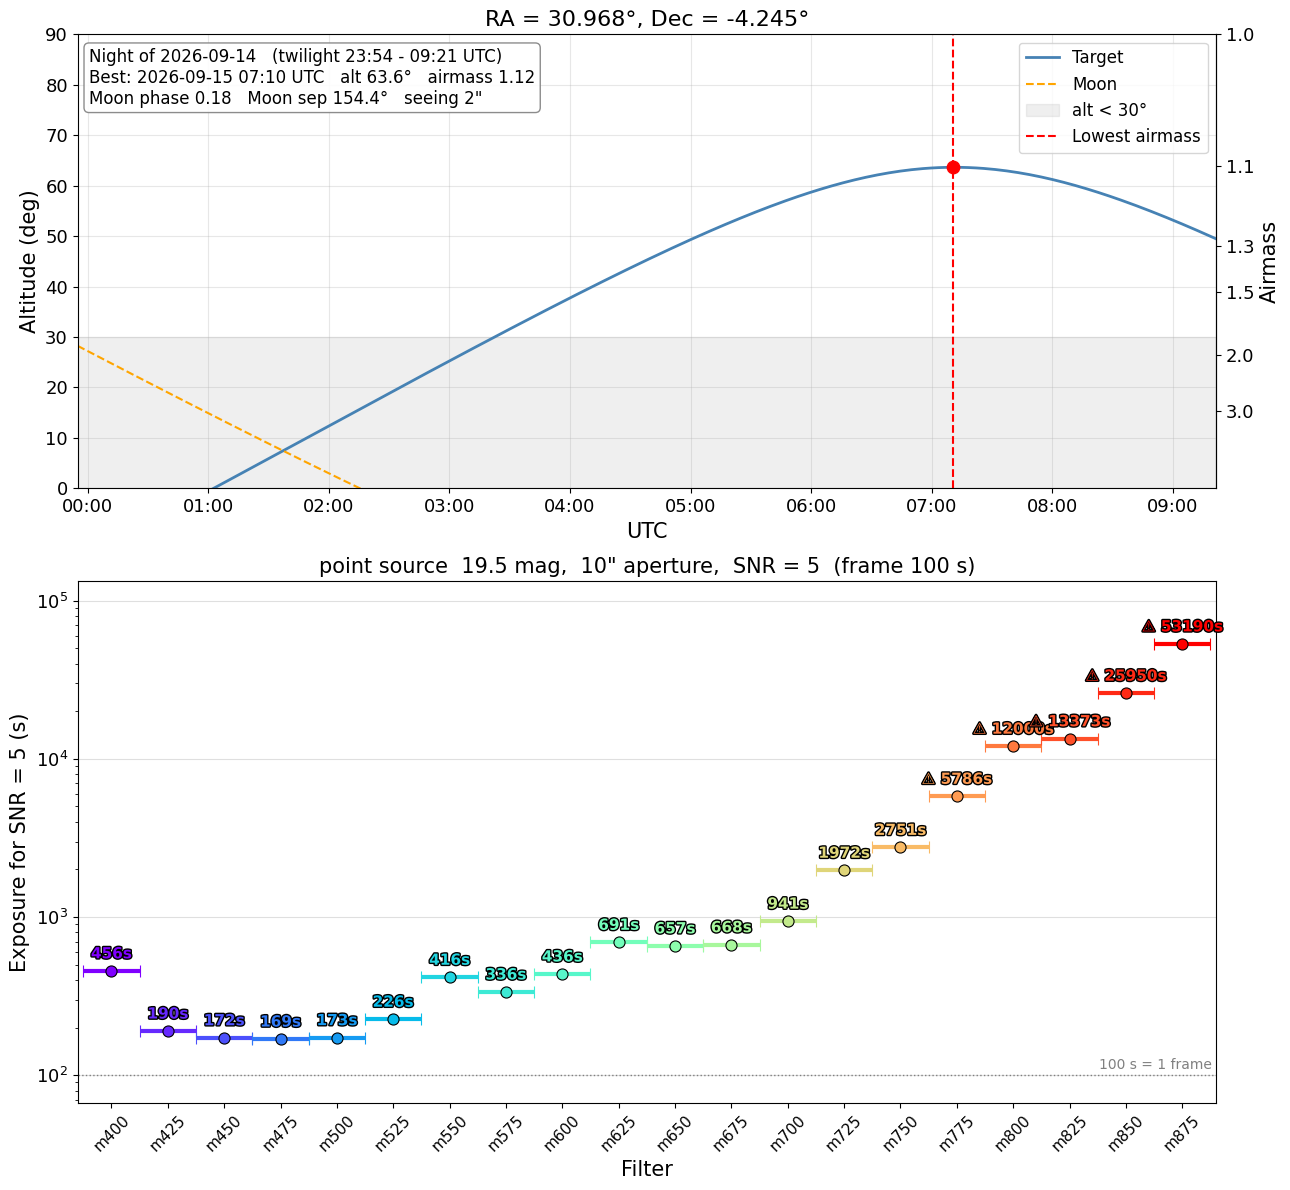

In [3]:
res_pt, info_pt = observe_and_etc(**TARGET, date='2026-09-14', value=19.5, snr=5, seeing=2.0)

반환값 `info`에는 관측 계획 정보가, `res`에는 필터별 계산 결과가 들어 있습니다.

In [4]:
print({k: info_pt[k] for k in ('best_time_utc', 'best_alt', 'airmass', 'moon_phase', 'moon_sep', 'hours_above_min_alt')})
pd.DataFrame(res_pt).T[['exptime', 'n_frame', 'frames']].head(8)

{'best_time_utc': '2026-09-15 07:10:50.779', 'best_alt': 63.64275938622841, 'airmass': 1.116017448096226, 'moon_phase': 0.18307480578753044, 'moon_sep': 154.3538088088821, 'hours_above_min_alt': 5.982121714577079}


,exptime,n_frame,frames
m400,456.42974,5,4x100s + 1x56.4s
m425,190.07734,2,1x100s + 1x90.1s
m450,172.327677,2,1x100s + 1x72.3s
m475,169.188117,2,1x100s + 1x69.2s
m500,172.616723,2,1x100s + 1x72.6s
m525,225.785197,3,2x100s + 1x25.8s
m550,415.618681,5,4x100s + 1x15.6s
m575,336.009321,4,3x100s + 1x36.0s


### 3-2. extended source: 24 mag/arcsec², 면적 100 arcsec², SNR 5

표면밝기(mag/arcsec²)를 측정 면적 안에서 SNR 5로 검출하는 데 필요한 시간입니다.

Target RA, Dec = 30.9680, -4.2450 | night of 2026-09-14
Astronomical twilight (UTC): 2026-09-14 23:54 -> 2026-09-15 09:21
Above 30 deg (UTC): 2026-09-15 03:23 -> 2026-09-15 09:21 (6.0 h)
Best time (lowest airmass): 2026-09-15 07:10:50 UTC, alt = 63.6 deg, airmass = 1.12
Moon phase = 0.18, Moon sep = 154.4 deg, seeing = 2"
extended source, 24.0 mag/arcsec^2, area 100 arcsec^2, SNR = 5, frame = 100 s

filter       T[s]  frames
m400        251.4  2x100s + 1x51.4s
m425         97.4  1x97.4s
m450         88.3  1x88.3s
m475         86.7  1x86.7s
m500         88.5  1x88.5s
m525        124.4  1x100s + 1x24.4s
m550        218.7  2x100s + 1x18.7s
m575        171.4  1x100s + 1x71.4s
m600        229.3  2x100s + 1x29.3s
m625        359.1  3x100s + 1x59.1s
m650        345.1  3x100s + 1x45.1s
m675        354.1  3x100s + 1x54.1s
m700        478.3  4x100s + 1x78.3s
m725       1024.0  10x100s + 1x24.0s
m750       1394.4  13x100s + 1x94.4s
m775       2955.5  29x100s + 1x55.5s
m800       6095.8  60x100s +

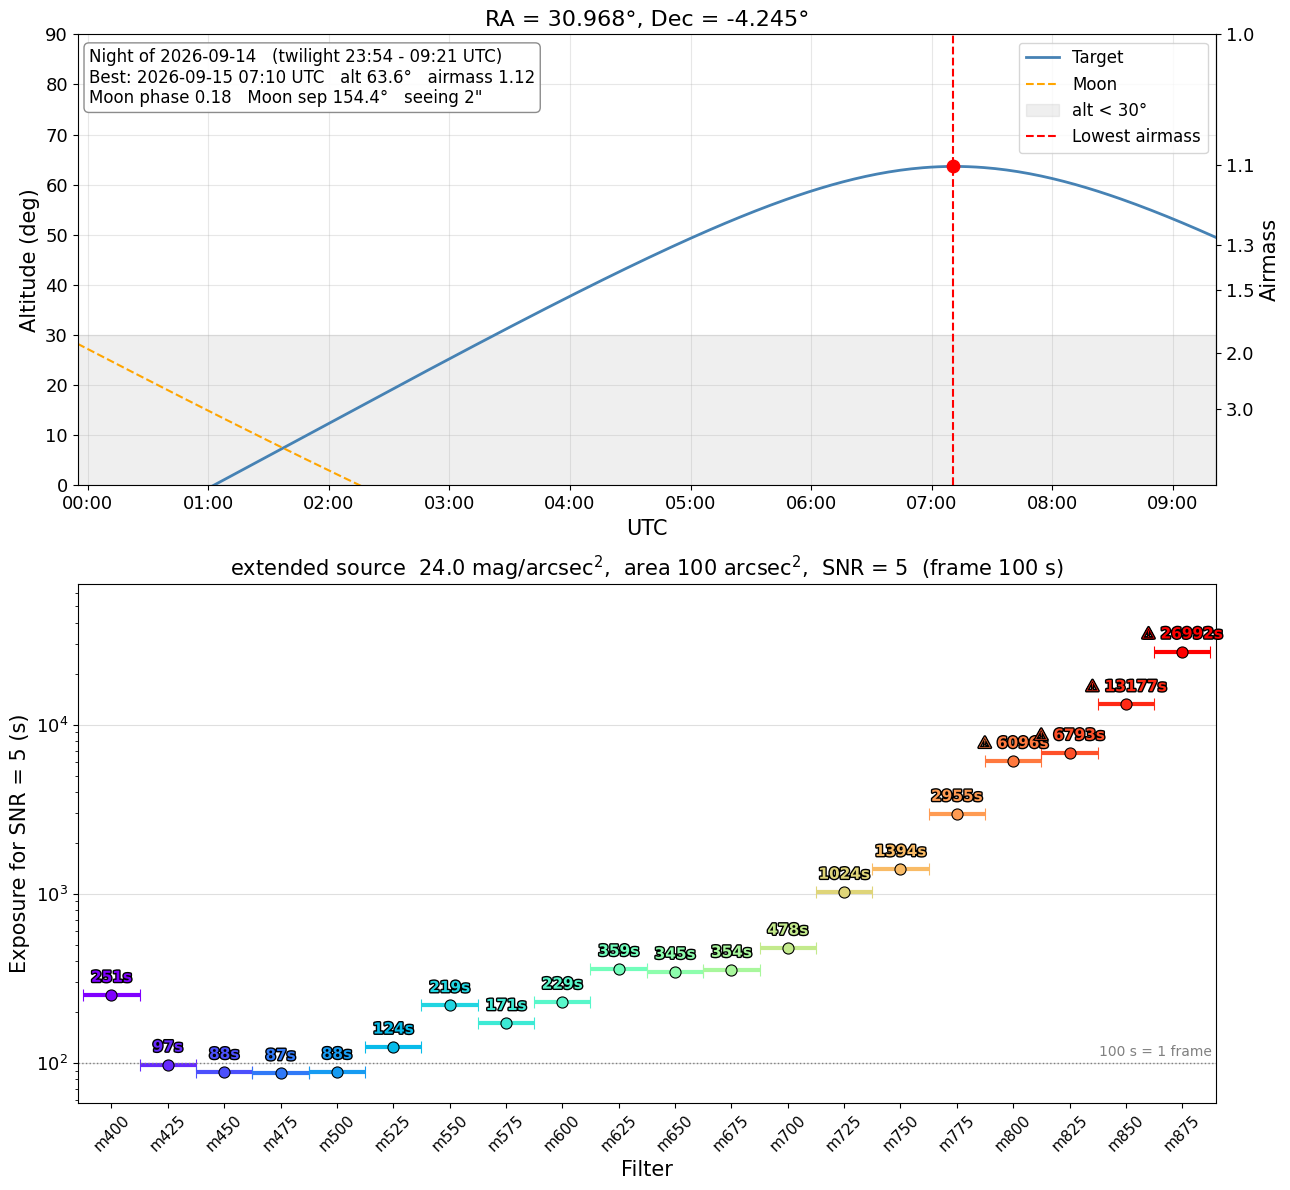

In [5]:
res_ex, info_ex = observe_and_etc(**TARGET, date='2026-09-14', value=24.0, snr=5, mode='extended', area=100, seeing=2.0)

## 4. 계산 함수

`ExposureCalculator`로 원하는 필터와 조건에서 직접 계산합니다. 기본은 10″ 구경 모델입니다.

| 함수 | 입력 | 출력 |
|---|---|---|
| `calculate_snr` | 밝기, 총 노출시간 | SNR, 분산 구성 비율 |
| `calculate_exptime` | 밝기, 목표 SNR | 필요 총 노출시간, 프레임 구성 |
| `calculate_limit` | 총 노출시간, SNR | 한계 등급 또는 한계 표면밝기 |

`filter='all'`은 g, r, i와 m400–m875(25 nm 간격)입니다.

In [6]:
calc = ExposureCalculator()          # 10" aperture
BANDS = ['m400', 'm500', 'm600', 'm700', 'm800', 'r']

### 4-1. 점광원

In [7]:
snr_pt = calc.calculate_snr(BANDS, 19.5, exptime=300, **cond_manual)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Point source, 10" aperture
Frame = 100 s
filter   value      T[s]      SNR  frames
m400     19.50     300.0     4.36  3x100s
m500     19.50     300.0     6.73  3x100s
m600     19.50     300.0     4.33  3x100s
m700     19.50     300.0     2.76  3x100s
m800     19.50     300.0     0.78  3x100s
r        19.50     300.0    10.14  3x100s
(value / limit in mag)



In [8]:
t_pt = calc.calculate_exptime(BANDS, 19.5, snr=10, **cond_manual)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Point source, 10" aperture
Frame = 100 s
filter   value   SNR       T[s]  frames
m400     19.50  10.0     1588.5  15x100s + 1x88.5s
m500     19.50  10.0      671.5  6x100s + 1x71.5s
m600     19.50  10.0     1597.4  15x100s + 1x97.4s
m700     19.50  10.0     3955.0  39x100s + 1x55.0s
m800     19.50  10.0    49722.2  497x100s + 1x22.2s
r        19.50  10.0      292.2  2x100s + 1x92.2s
(value / limit in mag)



In [9]:
lim_pt = calc.calculate_limit(BANDS, exptime=300, snr=5, **cond_manual)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Point source, 10" aperture
Frame = 100 s
filter      T[s]   SNR   limit  frames
m400       300.0   5.0   19.34  3x100s
m500       300.0   5.0   19.83  3x100s
m600       300.0   5.0   19.34  3x100s
m700       300.0   5.0   18.84  3x100s
m800       300.0   5.0   17.45  3x100s
r          300.0   5.0   20.28  3x100s
(value / limit in mag)



결과는 dict이므로 표로 바꿔 쓸 수 있습니다.
`frac_source / frac_sky / frac_read`는 전체 분산 중 각 노이즈 성분의 비율입니다.

In [10]:
pd.DataFrame(snr_pt).T[['value', 'exptime', 'frames', 'snr', 'frac_source', 'frac_sky', 'frac_read']].astype({'snr': float}).round(3)

,value,exptime,frames,snr,frac_source,frac_sky,frac_read
m400,19.5,300.0,3x100s,4.359,0.086098,0.084688,0.811187
m500,19.5,300.0,3x100s,6.728,0.082197,0.600608,0.3103
m600,19.5,300.0,3x100s,4.334,0.041167,0.767132,0.187533
m700,19.5,300.0,3x100s,2.759,0.034571,0.631866,0.326312
m800,19.5,300.0,3x100s,0.777,0.008095,0.76117,0.225719
r,19.5,300.0,3x100s,10.137,0.043307,0.917911,0.037939


### 4-2. extended source

`mode='extended'`와 측정 면적 `area` [arcsec²]를 줍니다. 값은 mag/arcsec² 단위입니다.

In [11]:
snr_ex = calc.calculate_snr(BANDS, 24.0, exptime=600, mode='extended', area=100, **cond_manual)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Extended source, area = 100 arcsec^2
Frame = 100 s
filter   value      T[s]      SNR  frames
m400     24.00     600.0     8.57  6x100s
m500     24.00     600.0    13.23  6x100s
m600     24.00     600.0     8.57  6x100s
m700     24.00     600.0     5.46  6x100s
m800     24.00     600.0     1.54  6x100s
r        24.00     600.0    20.03  6x100s
(value / limit in mag/arcsec^2)



In [12]:
lim_ex = calc.calculate_limit(BANDS, exptime=600, snr=3, mode='extended', area=100, **cond_manual)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Extended source, area = 100 arcsec^2
Frame = 100 s
filter      T[s]   SNR   limit  frames
m400       600.0   3.0   25.18  6x100s
m500       600.0   3.0   25.66  6x100s
m600       600.0   3.0   25.16  6x100s
m700       600.0   3.0   24.66  6x100s
m800       600.0   3.0   23.27  6x100s
r          600.0   3.0   26.09  6x100s
(value / limit in mag/arcsec^2)



측정 면적이 4배가 되면 (sky가 지배할 때) SNR은 2배가 됩니다.

In [13]:
for area in (25, 100, 400):
    r = calc.calculate_snr('m500', 25.0, exptime=1800, mode='extended', area=area, verbose=False, **cond_manual)['m500']
    print(f'area = {area:4d} arcsec^2   SNR = {r["snr"]:.2f}')

area =   25 arcsec^2   SNR = 4.71
area =  100 arcsec^2   SNR = 9.41
area =  400 arcsec^2   SNR = 18.82


## 5. 그림 함수

모든 그림에 계산 조건이 상자로 표시됩니다. `save_path='파일명.png'`를 주면 저장합니다.
중대역 색상은 m400(보라)–m875(빨강) 고정 스케일이라 그림마다 같은 밴드는 같은 색입니다.

### 5-1. 노출시간에 따른 SNR (점광원)

점선은 100 s depth를 √t로 단순 확장한 값입니다. 짧은 노출에서는 read noise 때문에 실제 SNR(실선)이 더 낮고,
100 s를 넘으면 프레임마다 read noise가 더해집니다.

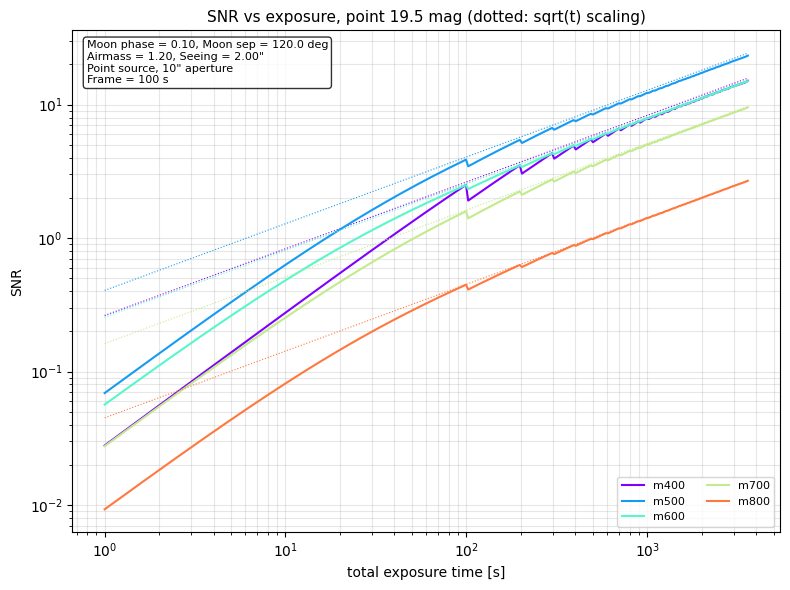

In [14]:
calc.plot_snr_vs_exptime(BANDS[:-1], 19.5, exptime_range=(1, 3600), **cond_manual)

### 5-2. 목표 SNR에 필요한 노출시간

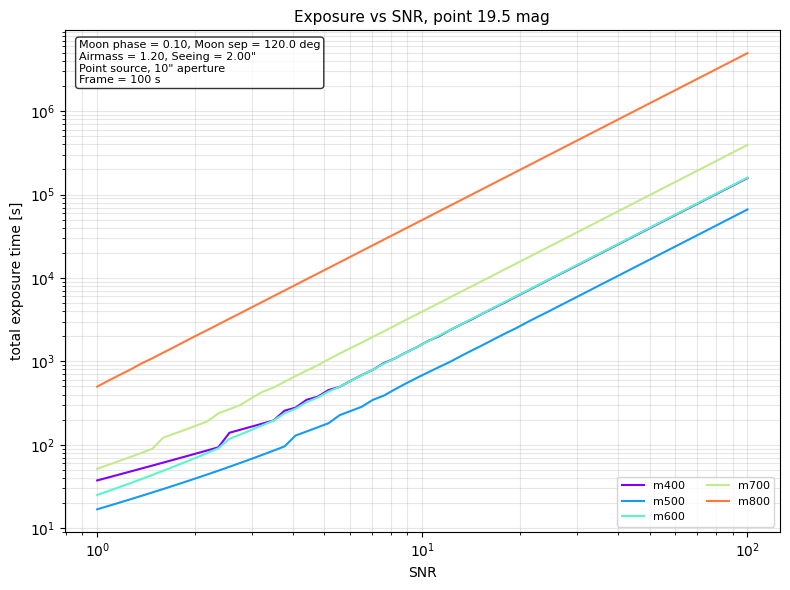

In [15]:
calc.plot_exptime_vs_snr(BANDS[:-1], 19.5, snr_range=(1, 100), **cond_manual)

### 5-3. 노출시간에 따른 한계 등급 (점광원, 5σ)

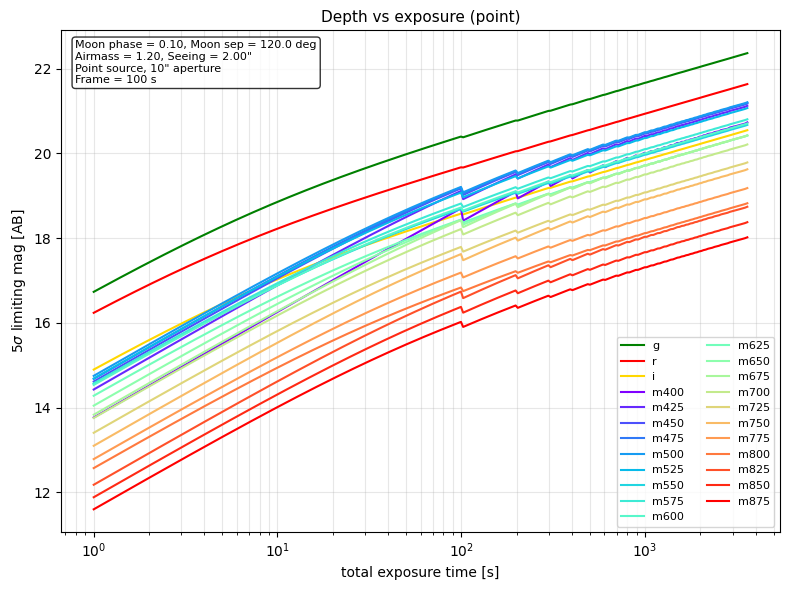

In [16]:
calc.plot_limit_vs_exptime('all', snr=5, **cond_manual)

### 5-4. 노출시간에 따른 한계 표면밝기 (extended, 3σ, 100 arcsec²)

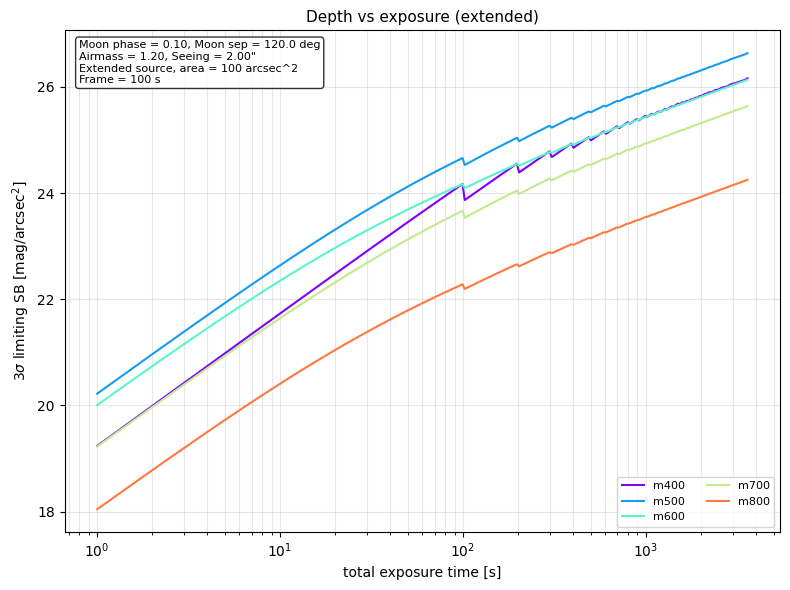

In [17]:
calc.plot_limit_vs_exptime(BANDS[:-1], snr=3, mode='extended', area=100, **cond_manual)

### 5-5. 노이즈 구성 (noise budget)

노출시간에 따라 어떤 노이즈가 지배하는지 보여줍니다. 짧은 노출은 read noise, 긴 노출은 sky가 지배합니다.
100 s 이후 비율이 일정해지는 것은 100 s 프레임마다 read noise가 다시 더해지기 때문입니다.

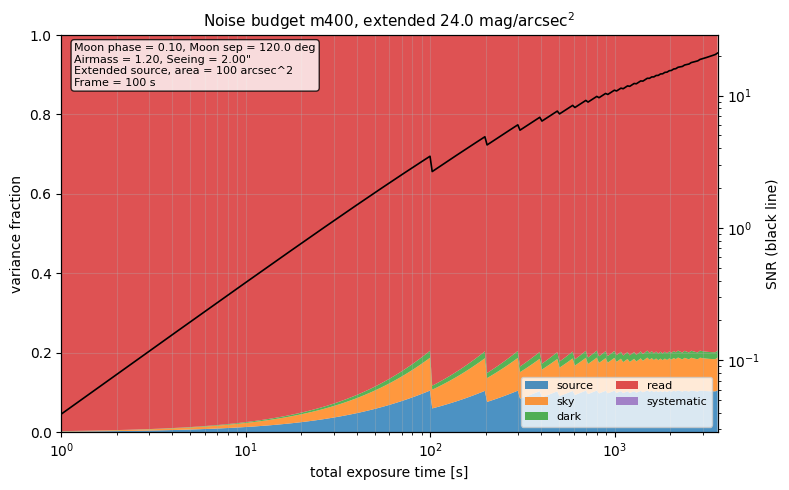

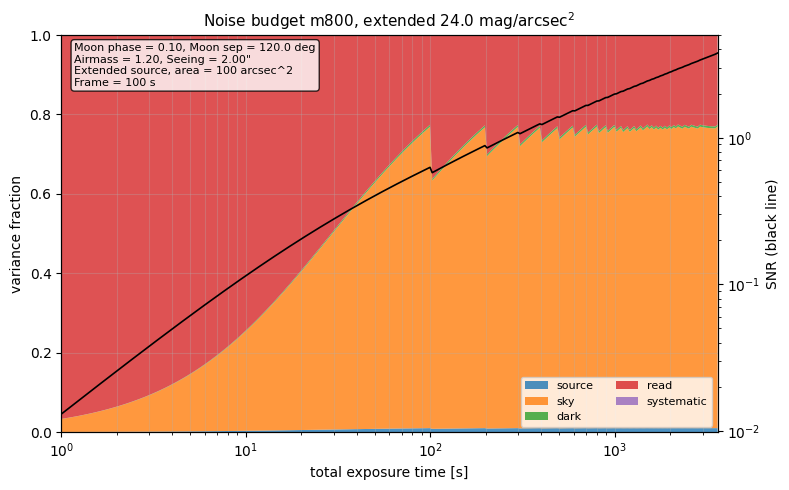

In [18]:
calc.plot_noise_budget('m400', 24.0, mode='extended', area=100, **cond_manual)
calc.plot_noise_budget('m800', 24.0, mode='extended', area=100, **cond_manual)

## 6. 5″ / 10″ 구경 비교 (점광원)

`ExposureCalculator(aperture=5)`로 5″ 구경 모델을 씁니다. 점광원은 작은 구경에서 sky 노이즈가 줄어 SNR이 높지만,
seeing이 나쁘면 구경 밖으로 빠지는 빛이 늘어납니다. extended source에는 구경 선택이 영향을 거의 주지 않습니다.

In [19]:
calc5 = ExposureCalculator(aperture=5)
r10 = calc.calculate_snr(BANDS, 19.5, exptime=300, verbose=False, **cond_manual)
r5 = calc5.calculate_snr(BANDS, 19.5, exptime=300, verbose=False, **cond_manual)
pd.DataFrame({'SNR_10"': {f: r10[f]['snr'] for f in BANDS}, 'SNR_5"': {f: r5[f]['snr'] for f in BANDS}}).assign(
    ratio=lambda d: d['SNR_5"'] / d['SNR_10"']).round(2)

,"SNR_10""","SNR_5""",ratio
m400,4.36,6.85,1.57
m500,6.73,10.98,1.63
m600,4.33,7.34,1.69
m700,2.76,4.69,1.70
m800,0.78,1.40,1.80
r,10.14,17.08,1.69


## 7. 100 s 프레임 분할

100 s를 넘는 총 노출은 100 s 프레임 k장 + 남는 시간 1장으로 계산합니다. 각 프레임마다 read noise가 한 번씩 더해지므로,
예를 들어 101 s(100 s + 1 s)는 100 s보다 SNR이 약간 낮을 수 있습니다. 실제 관측 계획은 100 s의 배수로 잡는 것이 효율적입니다.

In [20]:
_ = calc.calculate_snr('m500', 21.0, exptime=[50, 100, 101, 200, 350], **cond_manual)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Point source, 10" aperture
Frame = 100 s
filter   value      T[s]      SNR  frames
m500     21.00      50.0     0.62  1x50.0s
m500     21.00     100.0     1.01  1x100s
m500     21.00     101.0     0.88  1x100s + 1x1.0s
m500     21.00     200.0     1.42  2x100s
m500     21.00     350.0     1.84  3x100s + 1x50.0s
(value / limit in mag)



## 8. 기본 밴드와 추가 밴드

학습 프레임이 적거나 밴드 폭이 다른 필터(z, m438, m483, m512, m534, m561, m586, m615, m640, m661, m769w, m832w)는
`'all'`에서 빠집니다. 이름으로 직접 지정하면 경고와 함께 계산됩니다.

In [21]:
print("'all'      :", calc.filter_list('all'))
print("'available':", calc.filter_list('available'))
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always')
    calc.calculate_snr('m512', 19.5, exptime=300, verbose=False, **cond_manual)
    print('warning   :', w[0].message if w else None)

'all'      : ['g', 'r', 'i', 'm400', 'm425', 'm450', 'm475', 'm500', 'm525', 'm550', 'm575', 'm600', 'm625', 'm650', 'm675', 'm700', 'm725', 'm750', 'm775', 'm800', 'm825', 'm850', 'm875']
'available': ['g', 'r', 'i', 'z', 'm400', 'm425', 'm438', 'm450', 'm475', 'm483', 'm500', 'm512', 'm525', 'm534', 'm550', 'm561', 'm575', 'm586', 'm600', 'm615', 'm625', 'm640', 'm650', 'm661', 'm675', 'm700', 'm725', 'm750', 'm769w', 'm775', 'm800', 'm825', 'm832w', 'm850', 'm875']


## 9. 함수형 API (한 줄 계산)

계산기 객체 없이 바로 계산할 수 있습니다. `aperture=5`로 5″ 모델을 선택합니다.

In [22]:
_ = seventdt.calculate_exptime(19.5, snr=10, filters=['m400', 'm650'], **cond_manual)
_ = seventdt.calculate_limit(300, snr=3, filters=['m400', 'm650'], mode='extended', area=100, **cond_manual)
_ = seventdt.calculate_snr(19.5, 300, filters='m500', aperture=5, **cond_manual)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Point source, 10" aperture
Frame = 100 s
filter   value   SNR       T[s]  frames
m400     19.50  10.0     1588.5  15x100s + 1x88.5s
m650     19.50  10.0     2682.7  26x100s + 1x82.7s
(value / limit in mag)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Extended source, area = 100 arcsec^2
Frame = 100 s
filter      T[s]   SNR   limit  frames
m400       300.0   3.0   24.79  3x100s
m650       300.0   3.0   24.49  3x100s
(value / limit in mag/arcsec^2)

Moon phase = 0.10, Moon sep = 120.0 deg
Airmass = 1.20, Seeing = 2.00"
Point source, 5" aperture
Frame = 100 s
filter   value      T[s]      SNR  frames
m500     19.50     300.0    10.98  3x100s
(value / limit in mag)

